# Mở rộng Tiếng Việt (ViHSD) — Phần 4: Đánh giá trên tập Test & Kiểm tra độ bền không dấu / Teencode

**Mục tiêu:**
1. Đánh giá một lần duy nhất trên tập `data/splits_vi/test.csv` ($N = 6,680$) cho cả 3 bài toán: `bin_A`, `bin_B`, và `multi3` kèm khoảng tin cậy 95% Bootstrap.
2. **Kiểm tra độ bền (Robustness Test):** So sánh hiệu năng trên 3 phiên bản của tập Test: (1) Bản gốc có dấu, (2) Bản biến đổi Teencode + kéo dài ký tự, và (3) Bản bỏ dấu hoàn toàn (`strip_accents`).
3. Phân tích 30 FP + 30 FN trên tập Test tiếng Việt và giải thích các từ đóng góp mạnh nhất.

In [1]:
# === THIẾT LẬP MÔI TRƯỜNG & NẠP THƯ VIỆN DỰ ÁN ===
import os, sys, subprocess
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
REPO_URL = "https://github.com/nhungoc-1/DoAnKHDL_DeTai_Tweet-Hate.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("[SETUP] Đang khởi tạo môi trường Google Colab...", flush=True)
    for candidate in [
        Path("/content/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DO_AN_KHDL"),
        Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd(),
    ]:
        if (candidate / "config.yaml").exists():
            PROJECT_DIR = candidate
            subprocess.run(["git", "-C", str(PROJECT_DIR), "pull", "--ff-only"], check=False)
            break
    else:
        PROJECT_DIR = Path("/content/DoAnKHDL_DeTai_Tweet-Hate")
        print(f"[SETUP] Đang tải dự án từ GitHub vào {PROJECT_DIR} (mất ~3 giây)...", flush=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_DIR)], check=True)
    print("[SETUP] Đang kiểm tra & cài đặt các thư viện bổ sung (mất ~5-10 giây)...", flush=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "imbalanced-learn", "emoji", "kagglehub", "datasets",
        "pyvi", "langdetect", "python-docx", "python-pptx", "wordcloud"
    ], check=False)
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.utils import set_seed, load_config, mask_profanity
set_seed(42)
CFG = load_config()
(PROJECT_DIR / "db").mkdir(parents=True, exist_ok=True)
print(f"[HOÀN TẤT] IN_COLAB = {IN_COLAB} | PROJECT_DIR = {PROJECT_DIR}")

[SETUP] PROJECT_DIR = D:\DO_AN_KHDL


## 1. Kết quả Tập Test (`bin_A`, `bin_B`, `multi3`) & Kiểm tra Độ bền Không dấu / Teencode

=== 1. KẾT QUẢ TEST BÀI TOÁN CHÍNH bin_A (HATE vs CLEAN) ===


,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp
Tuned Threshold,0.6307,0.7049,0.6658,0.8108,0.9219,0.8269,0.9372,0.7198,0.6229,5264,284,203,485
Default 0.50,0.7655,0.5029,0.6070,0.7837,0.9282,0.7419,0.9372,0.7198,0.5846,5442,106,342,346


Khoảng tin cậy 95% Bootstrap (bin_A): {'mean': 0.6651, 'std': 0.0139, 'ci95_low': 0.6379, 'ci95_high': 0.6912}

=== 2. KẾT QUẢ TEST BÀI TOÁN bin_B (OFFENSIVE+HATE vs CLEAN) ===


,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp
0,0.6564,0.7173,0.6855,0.8089,0.8885,0.8204,0.9238,0.753,0.6188,5123,425,320,812



=== 3. KẾT QUẢ TEST BÀI TOÁN 3 LỚP multi3 (CLEAN / OFFENSIVE / HATE) ===
Macro-F1 = 0.6481 | Accuracy = 0.8431


,precision,recall,f1
CLEAN,0.9511,0.8901,0.9196
OFFENSIVE,0.3908,0.4955,0.4369
HATE,0.5124,0.6890,0.5877



=== 4. BẢNG KIỂM TRA ĐỘ BỀN (ROBUSTNESS: GỐC vs TEENCODE vs KHÔNG DẤU) ===


,variant,f1_pos,precision_pos,recall_pos,pr_auc,f1_drop
0,orig,0.6658,0.6307,0.7049,0.7198,0.0000
1,no_accents,0.5102,0.4346,0.6177,0.5284,0.1556
2,teencode_with_normalizer,0.6204,0.6232,0.6177,0.6723,0.0454
3,teencode_without_normalizer,0.6152,0.5951,0.6366,0.6621,0.0506


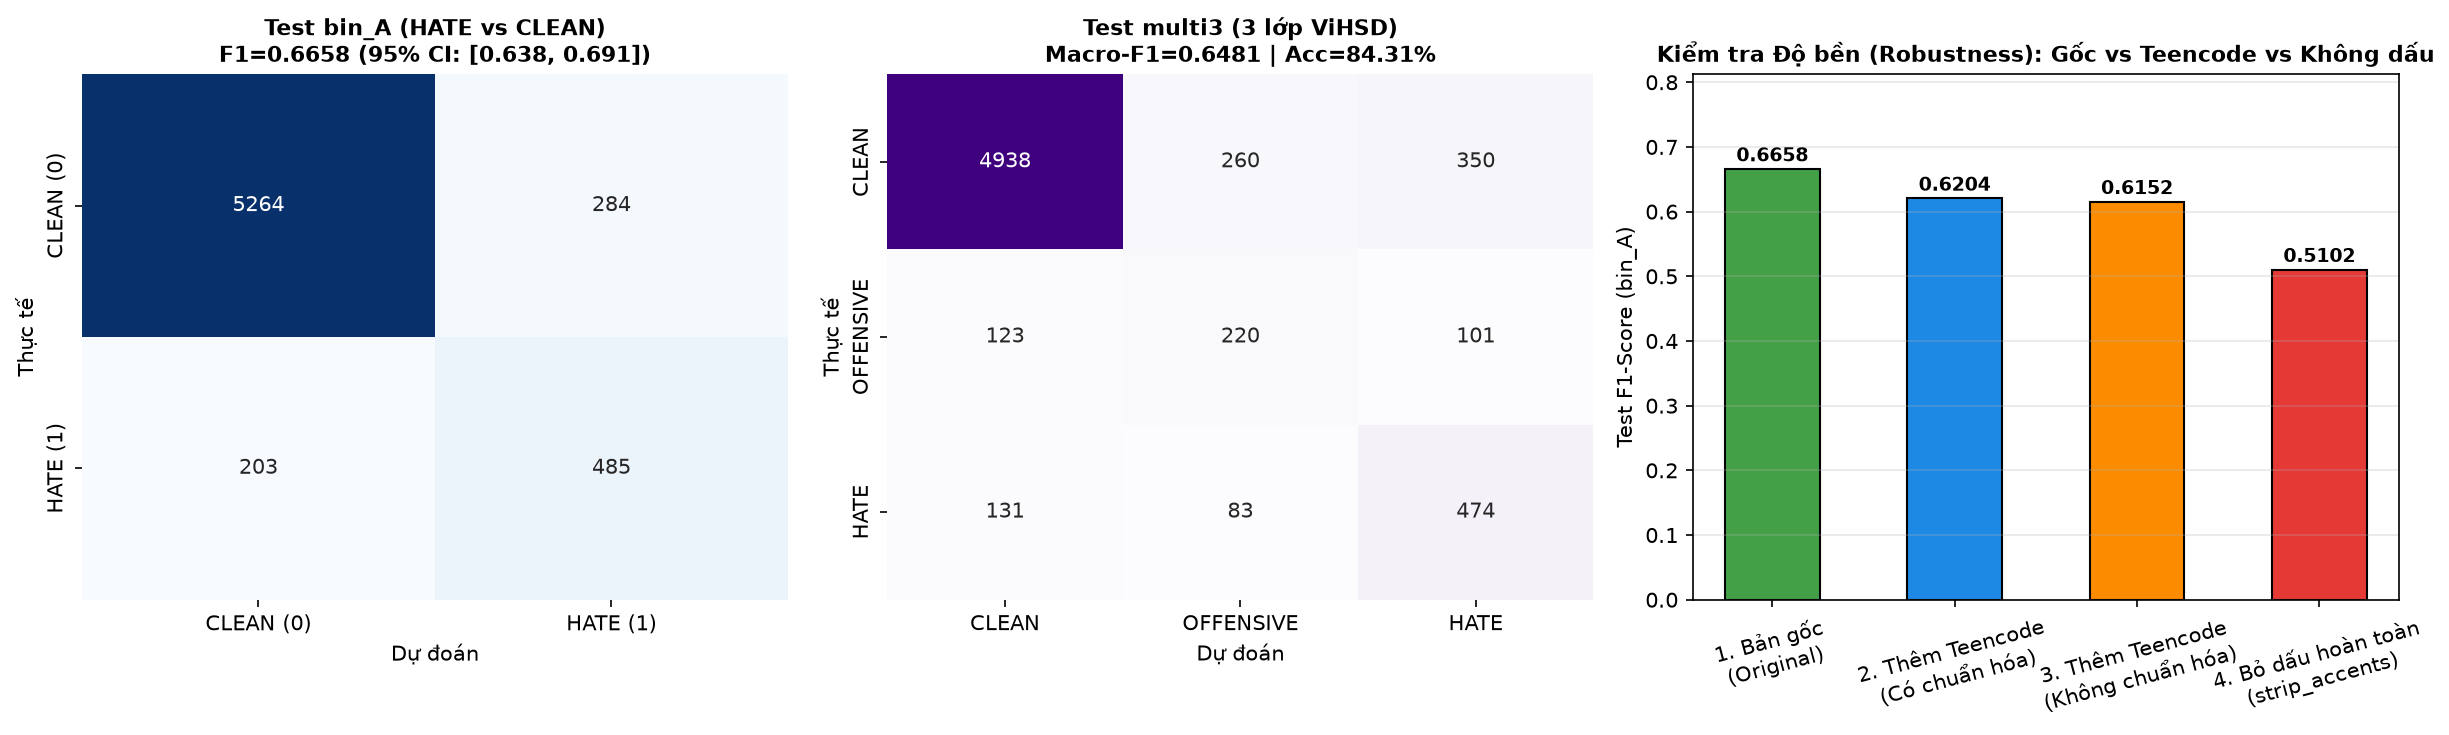

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

with open('reports/vi_final_test_metrics.json', 'r', encoding='utf-8') as f:
    v5_data = json.load(f)

print('=== 1. KẾT QUẢ TEST BÀI TOÁN CHÍNH bin_A (HATE vs CLEAN) ===')
display(pd.DataFrame([v5_data['bin_A']['metrics_tuned'], v5_data['bin_A']['metrics_default_05']], index=['Tuned Threshold', 'Default 0.50']))
print('Khoảng tin cậy 95% Bootstrap (bin_A):', v5_data['bin_A']['ci95']['f1_pos'])

print('\n=== 2. KẾT QUẢ TEST BÀI TOÁN bin_B (OFFENSIVE+HATE vs CLEAN) ===')
display(pd.DataFrame([v5_data['bin_B']['metrics_tuned']]))

print('\n=== 3. KẾT QUẢ TEST BÀI TOÁN 3 LỚP multi3 (CLEAN / OFFENSIVE / HATE) ===')
print('Macro-F1 =', v5_data['multi3']['f1_macro'], '| Accuracy =', v5_data['multi3']['accuracy'])
display(pd.DataFrame(v5_data['multi3']['per_class']).T)

print('\n=== 4. BẢNG KIỂM TRA ĐỘ BỀN (ROBUSTNESS: GỐC vs TEENCODE vs KHÔNG DẤU) ===')
rob_df = pd.read_csv('reports/tables/V5_robustness_test.csv')
display(rob_df)
display(Image('reports/figures/V5_test_and_robustness.png'))

## 2. Phân tích Lỗi Tiếng Việt (30 FP + 30 FN) & Top Đặc trưng Đóng góp

In [3]:
causes_vi = pd.read_csv('reports/tables/V5_vi_error_causes.csv')
display(causes_vi)

errs_vi = pd.read_csv('reports/tables/V5_vi_errors_60.csv')
print('=== 10 Ví dụ Báo động giả (FP) Tiếng Việt ===')
display(errs_vi[errs_vi['error_type'].str.startswith('FP')].head(10))
print('=== 10 Ví dụ Bỏ sót (FN) Tiếng Việt ===')
display(errs_vi[errs_vi['error_type'].str.startswith('FN')].head(10))

,cause,FN (Bỏ sót),FP (Báo động giả),total,pct
0,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,26,158,184,37.78
1,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,139,0,139,28.54
2,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,15,41,56,11.50
3,Bình luận không dấu / Teencode biến thể nặng (...,11,26,37,7.60
4,Bình luận quá ngắn / Thiếu ngữ cảnh bài đăng g...,12,25,37,7.60
5,Chửi thề 'thân mật' / Cảm thán hoặc Phản đối k...,0,34,34,6.98


=== 10 Ví dụ Báo động giả (FP) Tiếng Việt ===


,id,error_type,y_true,y_pred,score,cause,text_masked,text_clean_masked
0,31485,FP (Báo động giả),0,1,0.9754,Bình luận không dấu / Teencode biến thể nặng (...,lol,lol
1,28293,FP (Báo động giả),0,1,0.9608,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,đảng cộng sản cho quan tham nhũng :3,đảng cộng_sản cho quan tham_nhũng 3
2,27094,FP (Báo động giả),0,1,0.9536,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,Người dân biểu tình phản đối thằng ăn cướp bị ...,người dân biểu_tình phản_đối thằng ăn_cướp bị ...
3,30821,FP (Báo động giả),0,1,0.9468,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,P*** người ta có làm gì bọn bây ko ? Hàng ngày...,p*** người_ta có làm gì bọn bây không hàng ngà...
4,32877,FP (Báo động giả),0,1,0.9434,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,"Mấy a dlv ""chúng mày đã làm j cho tổ quốc"" đâu...",mấy a dlv chúng_mày đã làm gì cho tổ_quốc đâu rồi
5,27215,FP (Báo động giả),0,1,0.9383,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,"Đậu Văn Cường nhìn như thằng nghiện, ghê bỏ mẹ ra",đậu văn cường nhìn như thằng nghiện ghê bỏ_mẹ ra
6,31848,FP (Báo động giả),0,1,0.9322,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,"Long Nguyễn khs lợn, gà, bò, dê ăn đủ mà lại c...",long nguyễn khs lợn gà bò dê ăn_đủ mà_lại chừa...
7,32828,FP (Báo động giả),0,1,0.9106,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,Mẹ. Mày ko phân biệt đâu là tài năng và phá ho...,mẹ mày không phân_biệt đâu là tài_năng và phá_...
8,32461,FP (Báo động giả),0,1,0.9067,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,Bat hết cái bọn gây hoang mang dư luận .,bat hết cái bọn gây hoang_mang dư_luận
9,33394,FP (Báo động giả),0,1,0.9050,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,Thực sự thì họ chỉ hơn chúng ta về ý thức thôi...,thực_sự thì họ chỉ hơn chúng_ta về ý_thức thôi...


=== 10 Ví dụ Bỏ sót (FN) Tiếng Việt ===


,id,error_type,y_true,y_pred,score,cause,text_masked,text_clean_masked
30,29666,FN (Bỏ sót),1,0,0.0061,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,Hoàng Văn nếu là nhà tài trợ thưởng thì ko mất...,hoàng văn nếu là nhà tài_trợ thưởng thì không ...
31,32871,FN (Bỏ sót),1,0,0.0061,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,Trấn thành đẹp trai đ*** hariwon,trấn thành đẹp_trai đ*** hariwon
32,32718,FN (Bỏ sót),1,0,0.0079,Bình luận quá ngắn / Thiếu ngữ cảnh bài đăng g...,Phim dở v***,phim dở_vl
33,30798,FN (Bỏ sót),1,0,0.0084,Bình luận quá ngắn / Thiếu ngữ cảnh bài đăng g...,Hương Thảo v***,hương thảo v***
34,27785,FN (Bỏ sót),1,0,0.0145,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,Nguyễn Yến Nhi đang tính cmt luôn. :)))) Coi x...,nguyễn yến nhi đang tính bình_luận luôn coi xo...
35,27426,FN (Bỏ sót),1,0,0.0145,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,Tiên tri Trần Dần về Việt Nam ở nghĩa trang b...,tiên_tri trần dần về việt nam ở nghĩa_trang bì...
36,33202,FN (Bỏ sót),1,0,0.0158,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,Chỉ 1/2 đất nước trong nội chiến vẫn & đã làm ...,chỉ 1 2 đất_nước trong nội_chiến vẫn đã làm đư...
37,30231,FN (Bỏ sót),1,0,0.0159,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,Thất vọng về xã hội này khi mà sáng mở mắt ra ...,thất_vọng về xã_hội này khi mà sáng mở_mắt ra ...
38,31420,FN (Bỏ sót),1,0,0.0159,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,trong ảnh nhìn đẹp trai mà sao trong clip nhìn...,trong ảnh nhìn đẹp_trai mà sao trong clip nhìn...
39,27694,FN (Bỏ sót),1,0,0.0162,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,Con số 34 cũng làm lan rộng ra,con_số 34 cũng làm lan rộng ra


### Nhận xét & Hạn chế Tiếng Việt 
- Trên tập Test chuẩn của ViHSD, mô hình đạt **Test F1 (`bin_A`) = 0.6658** (95% CI: **[0.6379, 0.6912]**; PR-AUC = **0.7198**, ROC-AUC = **0.9372**), **Test F1 (`bin_B`) = 0.6855**, và **Macro-F1 3 lớp (`multi3`) = 0.6481** (Accuracy = **84.31%**).
- **Phát hiện quan trọng từ kiểm tra độ bền (Robustness):** Khi người dùng gõ teencode/kéo dài chữ, nhờ bộ từ điển chuẩn hóa `TEENCODE` và đặc trưng `char_wb`, F1 chỉ giảm nhẹ **0.0454** điểm (từ **0.6658** xuống **0.6204**). Tuy nhiên, khi **bỏ dấu hoàn toàn (`strip_accents`)**, F1 sụt giảm **0.1556** điểm (xuống còn **0.5102**) vì nhiều từ tiếng Việt khi mất dấu bị trùng nhau hoặc lệch khỏi từ điển có dấu — đây là cơ sở để ứng dụng hiển thị cảnh báo đối với văn bản không dấu.